# 20 · PAC answers from data: credal queries

A fitted network answers `P(recovered | treated)` with one number. That number
is computed on the *fitted* tables, and the tables carry the error of a finite
sample. The answer says nothing about how far it can be from the truth.

`pac_query` returns an **interval** instead. With probability at least
`1 - delta` over the data, the interval contains the true answer
`P_true(y | e)` or `P_true(y | e, do(x))`. It works in two steps:

1. Put a confidence set around every table row that the query reads. This step
   spends `delta` once, on the data.
2. Bound the query over **every** network whose rows lie in those sets. This is
   credal variable elimination; it is deterministic and spends no more
   confidence.

Ground truth (hidden from the learner), a small treatment network:

    A  age          (2 values)   P(A) = (0.6, 0.4)
    S  severity     (3 values)   depends on A
    T  treated      (2 values)   depends on S   (severe patients are treated more often)
    R  recovered    (2 values)   depends on S and T
    F  follow-up    (2 values)   depends on R   (a recovered patient rarely comes back)

`S` drives both `T` and `R`. So the observed `P(R | T = 1)` is not the
interventional `P(R | do(T = 1))` that a planner needs.

- **NBN API:** `nbn.uncertainty.pac_query`, `pac_sets`, `credal_query`, `CredalSets`, `QueryBounds`; `nbn.inference.certified_query` for comparison.
- **Runtime:** under 15 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn import NeuralBayesianNetwork
from nbn.inference import certified_query
from nbn.uncertainty import credal_query, pac_query, pac_sets
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, VERMILLION, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

CARD = {"A": 2, "S": 3, "T": 2, "R": 2, "F": 2}
PARENTS = {"A": [], "S": ["A"], "T": ["S"], "R": ["S", "T"], "F": ["R"]}
CPT = {                                                   # rows: parent values in the order above
    "A": torch.tensor([0.6, 0.4]),
    "S": torch.tensor([[0.6, 0.3, 0.1], [0.2, 0.4, 0.4]]),
    "T": torch.tensor([[0.85, 0.15], [0.5, 0.5], [0.15, 0.85]]),
    "R": torch.tensor([[[0.2, 0.8], [0.1, 0.9]],          # S = 0 (mild):     T = 0, T = 1
                       [[0.5, 0.5], [0.3, 0.7]],          # S = 1
                       [[0.85, 0.15], [0.6, 0.4]]]),      # S = 2 (severe)
    "F": torch.tensor([[0.3, 0.7], [0.8, 0.2]]),
}
ORDER = list(CARD)
EDGES = [(p, c) for c in ORDER for p in PARENTS[c]]


def exact(target: str, evidence: dict | None = None, do: dict | None = None) -> torch.Tensor:
    """True P(target | evidence, do) by enumerating the joint (48 cells)."""
    joint = torch.ones(*[CARD[n] for n in ORDER], dtype=torch.float64)
    for i, n in enumerate(ORDER):
        if do and n in do:                                 # do(): the node's row becomes a point mass
            table = torch.zeros(CARD[n], dtype=torch.float64)
            table[do[n]] = 1.0
            dims = [i]
        else:
            table, dims = CPT[n].double(), [ORDER.index(p) for p in PARENTS[n]] + [i]
        shape = [1] * len(ORDER)
        for d, j in enumerate(dims):
            shape[j] = table.shape[d]
        joint = joint * table.reshape(shape)
    for n, v in (evidence or {}).items():
        joint = joint.index_select(ORDER.index(n), torch.tensor([v]))
    marg = joint.sum([i for i, n in enumerate(ORDER) if n != target]).reshape(-1)
    return marg / marg.sum()


def simulate(n: int, seed: int) -> dict:
    """n i.i.d. rows from the true network (ancestral sampling)."""
    g = torch.Generator().manual_seed(seed)
    rows = {}
    for c in ORDER:
        probs = CPT[c][tuple(rows[p].long() for p in PARENTS[c])] if PARENTS[c] else CPT[c].expand(n, -1)
        rows[c] = torch.multinomial(probs, 1, generator=g).squeeze(-1).float()
    return {k: v.to(device) for k, v in rows.items()}


def fit(data: dict) -> NeuralBayesianNetwork:
    """Maximum-likelihood tables for the known DAG."""
    model = NeuralBayesianNetwork(EDGES, {k: ("discrete", v) for k, v in CARD.items()}, device=device)
    model.auto_mechanisms()                # count tables for discrete nodes
    model.fit(data)
    return model


def covers(bounds, truth: torch.Tensor, tol: float = 1e-9) -> bool:
    """Whether every class of the true answer lies in [lower, upper]."""
    return bool(((truth >= bounds.lower - tol) & (truth <= bounds.upper + tol)).all())


QUERIES = {                                               # name -> (target, evidence, do, class shown)
    "P(R=1 | T=1)": ("R", {"T": 1}, None, 1),
    "P(R=1 | do(T=1))": ("R", None, {"T": 1}, 1),
    "P(S=2 | F=0)": ("S", {"F": 0}, None, 2),
}
for name, (tgt, ev, do, y) in QUERIES.items():
    print(f"{name:18s} truth {float(exact(tgt, ev, do)[y]):.3f}")

device: cpu
P(R=1 | T=1)       truth 0.599
P(R=1 | do(T=1))   truth 0.722
P(S=2 | F=0)       truth 0.170


## 1. One number vs a guaranteed interval

We fit the network on 2000 rows and ask three queries: a conditional query, an
interventional query and a diagnostic query (from an effect back to a cause).
`pac_query` builds confidence sets only for the nodes the query reads (its
ancestral set) and returns a `QueryBounds`. Its fields are `lower` and `upper`
(one entry per class), `level = 1 - delta`, and `point`, the fitted model's
answer, for comparison.

In [2]:
DELTA = 0.1
data = simulate(2000, seed=0)
model = fit(data)

answers = {}
for name, (tgt, ev, do, y) in QUERIES.items():
    b = pac_query(model, data, tgt, ev, do=do, delta=DELTA)
    answers[name] = b
    truth = float(exact(tgt, ev, do)[y])
    print(f"{name:18s} fitted {float(b.point[y]):.3f} | PAC [{float(b.lower[y]):.3f}, {float(b.upper[y]):.3f}] "
          f"| truth {truth:.3f} | level {b.level:.2f} ({b.guarantee}) | contains the truth: {covers(b, exact(tgt, ev, do))}")

P(R=1 | T=1)       fitted 0.582 | PAC [0.437, 0.718] | truth 0.599 | level 0.90 (pac_under_model) | contains the truth: True
P(R=1 | do(T=1))   fitted 0.721 | PAC [0.591, 0.824] | truth 0.722 | level 0.90 (pac_under_model) | contains the truth: True
P(S=2 | F=0)       fitted 0.165 | PAC [0.089, 0.280] | truth 0.170 | level 0.90 (pac_under_model) | contains the truth: True


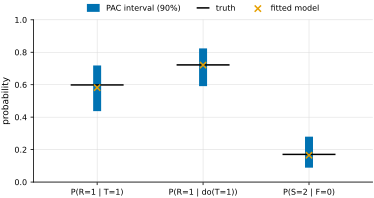

In [3]:
fig, ax = plt.subplots(figsize=(0.75 * DOUBLE, 2.8))
for i, (name, b) in enumerate(answers.items()):
    tgt, ev, do, y = QUERIES[name]
    ax.vlines(i, float(b.lower[y]), float(b.upper[y]), color=BLUE, lw=8,
              label=f"PAC interval ({1 - DELTA:.0%})" if i == 0 else None)
    ax.hlines(float(exact(tgt, ev, do)[y]), i - 0.25, i + 0.25, color=INK, lw=1.5,
              label="truth" if i == 0 else None)
    ax.scatter(i, float(b.point[y]), marker="x", s=40, color=ORANGE, zorder=3,
               label="fitted model" if i == 0 else None)
ax.set(xticks=range(len(answers)), xticklabels=list(answers), ylabel="probability", ylim=(0, 1),
       xlim=(-0.6, len(answers) - 0.4))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "20_point_vs_pac")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Three queries on a model fitted to 2000 rows. Blue bars: PAC
intervals at level 90%. Orange crosses: the fitted model's answers. Black
lines: the true answers.

The fitted answers are close to the truth here, but nothing in them says how
close. The intervals do: each one holds with probability at least 90% over the
data. Note the different targets: `P(R=1 | T=1)` and `P(R=1 | do(T=1))` differ,
because severe patients are both treated more often and recover less often.
The interventional query uses the same tables with `T` cut from its parent.

**Assumptions.** The guarantee needs discrete variables, i.i.d. rows
(`sampling="iid"`; use `"trajectory"` for episodes) and the correct DAG (or one
whose parent sets are supersets of the true ones). This is why `guarantee` reads
`"pac_under_model"`.

## 2. Width against the amount of data

Confidence sets shrink like `1 / sqrt(N)`, and so do the query bounds. Two
kinds of row sets are available:
- `kind="interval"`: per-entry KL intervals, with `delta` split over all table entries;
- `kind="l1"`: an L1 ball per row (Weissman), with `delta` split over all rows.

Below, the width of `P(R | do(T=1))` is averaged over 3 datasets per size.

In [4]:
SIZES = [1000, 3000, 10000, 30000, 100000]
widths = {"interval": [], "l1": []}
for n in SIZES:
    for kind in widths:
        w = []
        for s in range(3):
            d = simulate(n, seed=10 + s)
            w.append(pac_query(fit(d), d, "R", do={"T": 1}, delta=DELTA, kind=kind).max_width)
        widths[kind].append(sum(w) / len(w))
for kind, w in widths.items():
    print(f"{kind:9s}", "  ".join(f"N={n}: {x:.3f}" for n, x in zip(SIZES, w)))

interval  N=1000: 0.305  N=3000: 0.189  N=10000: 0.103  N=30000: 0.061  N=100000: 0.033
l1        N=1000: 0.347  N=3000: 0.227  N=10000: 0.129  N=30000: 0.074  N=100000: 0.041


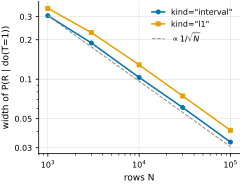

In [5]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
ax.plot(SIZES, widths["interval"], "o-", color=BLUE, label='kind="interval"')
ax.plot(SIZES, widths["l1"], "s-", color=ORANGE, label='kind="l1"')
guide = [widths["interval"][0] * (SIZES[0] / n) ** 0.5 for n in SIZES]
ax.plot(SIZES, guide, ls="--", color=GREY, lw=1, label=r"$\propto 1/\sqrt{N}$")
ax.set(xscale="log", yscale="log", xlabel="rows N", ylabel="width of P(R | do(T=1))")
ax.set_yticks([0.03, 0.05, 0.1, 0.2, 0.3], labels=["0.03", "0.05", "0.1", "0.2", "0.3"])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.legend()
save(fig, "20_width_vs_n")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Largest class width of the 90% PAC bound on `P(R | do(T = 1))`
against the number of rows (mean over 3 datasets per size; log-log axes). Blue:
interval sets. Orange: L1 balls. Dashed: a `1 / sqrt(N)` guide through the
first blue point.

The width falls like `1 / sqrt(N)`: 100 times more data gives intervals about
10 times narrower. On this network the per-entry intervals are a little
narrower than the L1 balls.

## 3. Do the intervals keep their promise?

Over 50 fresh datasets of 2000 rows, each query's interval should contain the
truth in at least 90% of them. Each `pac_query` call spends its own `delta`, so
the promise holds **per query**.

In [6]:
N_DATA, N_REP = 2000, 50
reps = []
for r in range(N_REP):                      # fit once per dataset; reused in sections 3-5
    d = simulate(N_DATA, seed=100 + r)
    reps.append((d, fit(d)))

hits = dict.fromkeys(QUERIES, 0)
do_bounds = []
for d, m in reps:
    for name, (tgt, ev, do, y) in QUERIES.items():
        b = pac_query(m, d, tgt, ev, do=do, delta=DELTA)
        hits[name] += covers(b, exact(tgt, ev, do))
        if name == "P(R=1 | do(T=1))":
            do_bounds.append(b)
for name, h in hits.items():
    print(f"{name:18s} contains the truth in {h}/{N_REP} datasets (promise: at least {1 - DELTA:.0%})")

P(R=1 | T=1)       contains the truth in 50/50 datasets (promise: at least 90%)
P(R=1 | do(T=1))   contains the truth in 50/50 datasets (promise: at least 90%)
P(S=2 | F=0)       contains the truth in 50/50 datasets (promise: at least 90%)


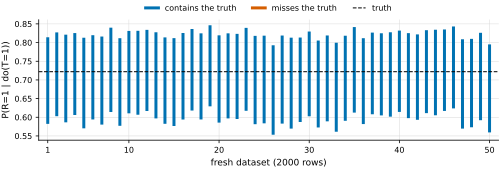

In [7]:
truth_do = float(exact("R", do={"T": 1})[1])
fig, ax = plt.subplots(figsize=(DOUBLE, 2.4))
for r, b in enumerate(do_bounds):
    ok = float(b.lower[1]) <= truth_do <= float(b.upper[1])
    ax.vlines(r + 1, float(b.lower[1]), float(b.upper[1]), color=BLUE if ok else VERMILLION, lw=3)
ax.axhline(truth_do, color=INK, lw=1, ls="--")
ax.set(xlabel="fresh dataset (2000 rows)", ylabel="P(R=1 | do(T=1))", xlim=(0, N_REP + 1),
       xticks=[1, 10, 20, 30, 40, 50])
handles = [plt.Line2D([], [], color=BLUE, lw=3), plt.Line2D([], [], color=VERMILLION, lw=3),
           plt.Line2D([], [], color=INK, lw=1, ls="--")]
ax.legend(handles, ["contains the truth", "misses the truth", "truth"],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "20_coverage")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** The 90% PAC interval for `P(R = 1 | do(T = 1))` on each of 50 fresh
datasets (bars; blue: contains the truth, red: misses it) and the truth
(dashed).

Coverage is usually above the promise. The bound is a union bound over many
table entries followed by a relaxation (credal elimination optimises each row
separately in every context), so it is sound but conservative.

## 4. Many queries from one set of tables

To ask many questions of the same data, build the sets **once** with
`pac_sets` and answer each query with `credal_query`. `pac_sets` splits `delta`
over all entries of all tables, a split fixed before the data are seen. So
every answer computed from these sets holds **at the same time** with
probability at least `1 - delta`, not just one query at a time.

In [8]:
joint_hits = 0
for d, m in reps:
    sets = pac_sets(m, d, delta=DELTA)              # a CredalSets: {node: set}, joint level 0.9
    joint_hits += all(covers(credal_query(m, sets, tgt, ev, do=do), exact(tgt, ev, do))
                      for tgt, ev, do, _ in QUERIES.values())
print(f"sets: {sorted(sets)} | joint level {sets.level:.2f}")
print(f"all {len(QUERIES)} queries contained the truth together in {joint_hits}/{N_REP} datasets "
      f"(promise: at least {1 - DELTA:.0%})")

sets: ['A', 'F', 'R', 'S', 'T'] | joint level 0.90
all 3 queries contained the truth together in 50/50 datasets (promise: at least 90%)


### Rows without data are the whole simplex

Suppose the logging policy **never treats mild patients** (`S = 0`). The row
`P(R | S = 0, T = 1)` then has no data. Its set is the whole simplex (the
`unseen` mask of the set; row 1 is `S = 0, T = 1`, rows in C order over the parents), and `credal_query` lets that row take any value. The
interventional answer stays sound but becomes wide: mild patients make up a
large share of the population, and the data say nothing about treating them.
No method can do better from these data alone.

In [9]:
def never_treat_mild(d: dict) -> dict:
    keep = ~((d["S"] == 0) & (d["T"] == 1))
    return {k: v[keep] for k, v in d.items()}


logs = {"every patient can be treated": simulate(5000, seed=7),
        "mild patients never treated": never_treat_mild(simulate(5000, seed=7))}
gap_bounds = {}
for name, d in logs.items():
    m = fit(d)
    sets = pac_sets(m, d, delta=DELTA)
    unseen = sets["R"].unseen.nonzero().flatten().tolist()
    gap_bounds[name] = b = credal_query(m, sets, "R", do={"T": 1})
    print(f"{name:30s} rows of R without data: {unseen} | P(R=1 | do(T=1)) in "
          f"[{float(b.lower[1]):.3f}, {float(b.upper[1]):.3f}] | truth {truth_do:.3f}")

every patient can be treated   rows of R without data: [] | P(R=1 | do(T=1)) in [0.625, 0.779] | truth 0.722
mild patients never treated    rows of R without data: [1] | P(R=1 | do(T=1)) in [0.277, 0.794] | truth 0.722


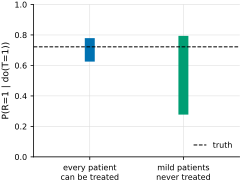

In [10]:
fig, ax = plt.subplots(figsize=(SINGLE, 2.6))
for i, (name, b) in enumerate(gap_bounds.items()):
    ax.vlines(i, float(b.lower[1]), float(b.upper[1]), color=(BLUE, AQUA)[i], lw=10)
ax.axhline(truth_do, color=INK, lw=1, ls="--", label="truth")
ax.set(xticks=[0, 1], xticklabels=["every patient\ncan be treated", "mild patients\nnever treated"],
       ylabel="P(R=1 | do(T=1))", ylim=(0, 1), xlim=(-0.6, 1.6))
ax.legend(loc="lower right")
save(fig, "20_unseen_rows")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** The 90% bound on `P(R = 1 | do(T = 1))` from 5000 logged rows,
under two logging policies (bars), and the truth (dashed). When mild patients
are never treated, one row of `R` has no data and is left free, so the bound
becomes much wider: mild patients are 44% of the population
(`P(S = 0) = 0.6 * 0.6 + 0.4 * 0.2`), and for them the data say nothing about
treatment.

## 5. Learning error vs inference error

`certified_query` also returns intervals, but they answer a different question.
They bound the **sampling error of inference on the fitted model**: the gap
between a Monte Carlo estimate and the exact answer of *that* model. They know
nothing about the data the model was fitted on. With enough samples they
shrink around the fitted answer, which itself misses the truth by the learning
error.

The PAC bound covers learning error; the certified bound covers inference
error. Below, both are computed for `P(R = 1 | do(T = 1))` on the same 50
datasets.

In [11]:
torch.manual_seed(0)                        # certified_query samples with torch's global generator
cert_hits, cert = 0, []
for d, m in reps:
    c = certified_query(m, "R", do={"T": 1}, n_samples=20_000, delta=DELTA)
    cert.append(c)
    cert_hits += covers(c, exact("R", do={"T": 1}))
pac_hits = sum(covers(b, exact("R", do={"T": 1})) for b in do_bounds)
print(f"certified (inference error only): contains the truth in {cert_hits}/{N_REP} datasets, "
      f"median width {torch.tensor([c.max_width for c in cert]).median():.3f}")
print(f"PAC (learning error):             contains the truth in {pac_hits}/{N_REP} datasets, "
      f"median width {torch.tensor([b.max_width for b in do_bounds]).median():.3f}")

certified (inference error only): contains the truth in 24/50 datasets, median width 0.020
PAC (learning error):             contains the truth in 50/50 datasets, median width 0.229


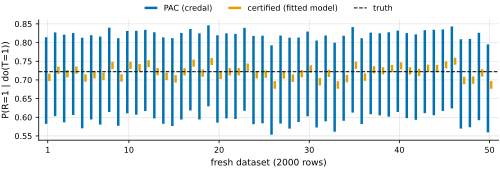

In [12]:
fig, ax = plt.subplots(figsize=(DOUBLE, 2.4))
for r, (b, c) in enumerate(zip(do_bounds, cert)):
    ax.vlines(r + 1 - 0.18, float(b.lower[1]), float(b.upper[1]), color=BLUE, lw=2.5,
              label="PAC (credal)" if r == 0 else None)
    ax.vlines(r + 1 + 0.18, float(c.lower[1]), float(c.upper[1]), color=ORANGE, lw=2.5,
              label="certified (fitted model)" if r == 0 else None)
ax.axhline(truth_do, color=INK, lw=1, ls="--", label="truth")
ax.set(xlabel="fresh dataset (2000 rows)", ylabel="P(R=1 | do(T=1))", xlim=(0, N_REP + 1),
       xticks=[1, 10, 20, 30, 40, 50])
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "20_learning_vs_inference")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** For each of the 50 datasets: the 90% PAC interval (blue) and the
90% certified interval of the fitted model (orange) for `P(R = 1 | do(T = 1))`,
and the truth (dashed). The certified intervals are narrow and follow each
fitted model, so many of them miss the truth. The PAC intervals are wider and
contain it.

**When to use which:**
- `pac_query` / `credal_query` when the question is about the real system and
  the tables were learned from limited data (discrete variables);
- `certified_query` when the model is taken as given and the only doubt is the
  sampling error of inference, for example on a network too large for exact
  inference.